# 03 · Orbit Bump: excite a desired bump

## What the GUI solves

After **Read reference orbit** the GUI stores the reference orbit $\mathbf b_{ref}$ and the corrector settings to restore. You then give targets to some BPMs (double-click a BPM or drag a point in the plot). The desired orbit at every **selected** BPM is
$$d_i=\begin{cases}t_i & \text{BPM with a target}\\ b_{ref,i} & \text{all other selected BPMs}\end{cases}$$
so every selected BPM without a target is asked to stay at the reference. That is what closes the bump. With the current orbit $\mathbf b$,
$$\Delta\mathbf c=R^+(\mathbf d-\mathbf b)\qquad\text{or, with Beta }\beta>0,\qquad \Delta\mathbf c=(R^TR+\beta I)^{-1}R^T(\mathbf d-\mathbf b).$$
The new settings $\mathbf c+\Delta\mathbf c$ are clipped to $\pm$**Max strength**, and the prediction is $\mathbf b+R\,\Delta\mathbf c$ with the clipped $\Delta\mathbf c$. $R$ contains both planes, so vertical correctors can cancel the vertical orbit that a horizontal kick couples in. Beta is a regularization weight, unrelated to the Twiss β function.

A closed bump with $m$ target BPMs therefore needs at least $m+2$ correctors per plane, with correctors on both sides of the targets. The classic 3-corrector bump has one target.

**Run:** follow [the setup guide](README.md), select the **Flight tutorials** kernel, then **Restart Kernel and Run All Cells**.

All BPMs selected: H kicks [ 0.065 -0.054 -0.1  ] mrad, V kicks [-0.0009 -0.0013  0.0062] mrad
BPM1, BPM2 deselected: H kicks [ 0.299 -0.597  0.298] mrad, V kicks [-0.0082  0.0163 -0.0077] mrad


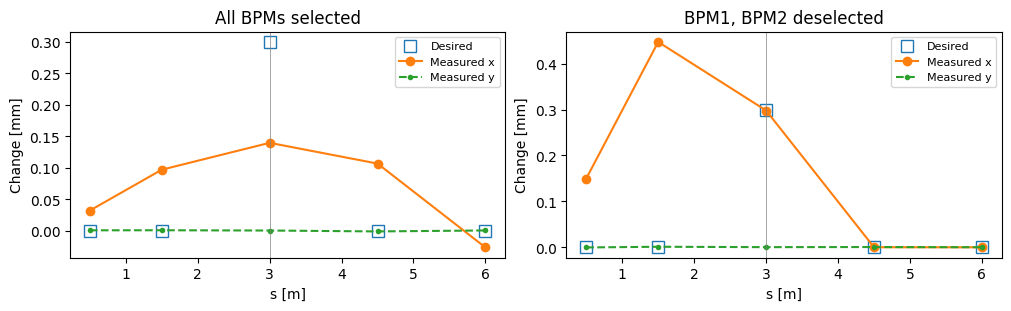

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Beamline, orbit_vector, measured_response, response_block

machine = Beamline(seed=13)
initial = machine.settings.copy()
R = response_block(measured_response(machine))
reference = orbit_vector(machine)
desired = reference.copy()
desired[2] += 0.3

def solve(R, residual, rcond=1e-3, beta=0.0):
    if beta > 0:
        return np.linalg.solve(R.T @ R + beta * np.eye(R.shape[1]), R.T @ residual)
    return np.linalg.pinv(R, rcond=rcond) @ residual

def compute_and_apply(rows, limit=1.0):
    machine.set_correctors(machine.correctors, initial)
    delta = solve(R[rows], (desired - orbit_vector(machine))[rows])
    new = np.clip(initial + delta, -limit, limit)
    machine.set_correctors(machine.correctors, new)
    return new, orbit_vector(machine)

all_rows = np.arange(10)
bump_rows = np.array([2, 3, 4, 5, 6, 7, 8, 9])
results = {'All BPMs selected': compute_and_apply(all_rows), 'BPM1, BPM2 deselected': compute_and_apply(bump_rows)}
machine.set_correctors(machine.correctors, initial)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for (label, (settings, measured)), ax in zip(results.items(), axes):
    ax.plot(machine.s_bpms, (desired - reference)[:5], 's', mfc='none', ms=9, label='Desired')
    ax.plot(machine.s_bpms, (measured - reference)[:5], 'o-', label='Measured x')
    ax.plot(machine.s_bpms, (measured - reference)[5:], '.--', label='Measured y')
    ax.axvline(3.0, color='gray', lw=0.5)
    ax.set(xlabel='s [m]', ylabel='Change [mm]', title=label)
    ax.legend(fontsize=8)
    print(f'{label}: H kicks {np.round(settings[:3], 3)} mrad, V kicks {np.round(settings[3:], 4)} mrad')
plt.show()

## Choosing the parameters

| GUI field | Default | How to choose |
|---|---|---|
| Directory | – | SysID *Orbit* directory measured on the same interface; the GUI refuses data from another interface. |
| BPMs | all | Keep the BPMs that must stay at the reference (upstream of the first corrector and downstream of the bump). Deselect BPMs inside the bump that you do not constrain. |
| Correctors | all | At least $m+2$ per plane for $m$ targets, with correctors on both sides of the targets. |
| Desired bump | none | Absolute positions in BPM units. Check the prediction before applying. |
| PINV tolerance | $10^{-3}$ | (see [Response Matrix](02_ResponseMatrix.ipynb))|
| Beta parameter | 0 | 0 uses the pseudoinverse. Use it for noisy or nearly dependent correctors. |
| Max strength H/V | from the interface | Absolute limits. Clipping happens after the solution, so a clipped bump does not close; check the predicted orbit. |
| BPM samples | 3 | Larger in the presence of jitter.|

**Try:** in `compute_and_apply`, use `limit=0.4` for the deselected case: HC2 is clipped and the bump no longer closes. **Restore reference** sets the correctors saved with the reference orbit. Continue with [Beam-Based Alignment](04_BeamBasedAlignment.ipynb).